# Lab 12 · Biểu đồ cho báo cáo và cách kiểm tra bằng `assert`

**Lập trình xử lý dữ liệu (LTXLDL) · 2627-1 · Giờ thực hành · Bài 12**

> 💡 File → **Save a copy in Drive** trước khi sửa.

Notebook bài giảng bài 12 giới thiệu bốn dạng biểu đồ cơ bản. Trong lab này, bạn sẽ tạo
**biểu đồ tự động từ mã nguồn, đủ thành phần để xuất bản và được lưu vào `figures/`**.
Bạn cũng sẽ dùng `assert` để kiểm tra cấu trúc biểu đồ như các kết quả khác.

*Lab khoảng 50 phút; 30 phút cuối dành cho phần hỗ trợ bài tập lớn ở cuối notebook.*

**Mục tiêu bài lab**

1. Dựng ba hình hoàn chỉnh bằng `fig, ax`, với tiêu đề nêu thông điệp, nhãn trục, đơn vị và nguồn.
2. Lưu hình vào `figures/` bằng `savefig` — sản phẩm của pipeline.
3. Kiểm tra hình bằng mã nguồn: đã có tiêu đề, trục bắt đầu từ 0 và đủ số thanh hay chưa.
4. Sửa một biểu đồ gây hiểu sai thành biểu đồ trung thực.

Phiên bản đề: `report-charts-v1` (25/09/2026). Lưu đúng tên **`lab-12.ipynb`**.

## Cách làm và nộp bài

- Với phần có hướng dẫn, bạn nên **tự gõ, không dùng AI** — các bài kiểm tra định kỳ 🚫 đóng ở giờ lý thuyết
  kiểm tra những kỹ năng này. Bài tự làm cuối lab ở chế độ ✅ mở: được dùng AI, kèm khai báo.
- Điền thân hàm TODO và phần trả lời Markdown. Mỗi hàm vẽ **tạo hình mới** bằng `fig, ax = plt.subplots(...)`,
  lưu bằng `fig.savefig(path, dpi=150, bbox_inches="tight")` và **trả về `ax`**.
- Giữ tên hàm, tham số, cell ID và metadata; viết helper/import thêm trong chính cell bài làm
  (`plt` đã được import sẵn trong cell bài làm). Grader chỉ chạy cell câu đó với dữ liệu riêng, rồi đọc cấu trúc
  của `ax` trả về: dữ liệu trên đường/thanh, tiêu đề, nhãn trục, giới hạn trục, chữ trên hình và file đã lưu.
  Grader không phụ thuộc biến `ds`, `rv`, `thang_pro` ở cell khác. `pd`, `np` được cung cấp sẵn.
- Public checks chỉ là ví dụ tự kiểm tra trên dữ liệu giả lập. Một check lỗi không dừng các check sau.
  TODO báo **CHƯA LÀM**; lỗi cú pháp vẫn cần sửa. Không sửa input; không ghi cứng kết quả.
- **Restart & Run all**, lưu notebook, commit/push vào repo của bạn trong org và tạo tag theo cuối bài.
  Không commit thư mục `figures/` do notebook tạo ra.

## Rubric dự kiến — 100 điểm

| Mục | Điểm | Cách đánh giá |
|---|---:|---|
| Bài 1 (chuỗi tháng) 15 · Bài 2 (biểu đồ đường) 15 · Bài 3 (bảng tỷ lệ) 10 | 40 | Tự động |
| Bài 4 (thanh ngang) 15 · Bài 5 (histogram) 15 · Bài 6 (sửa trục bị cắt) 10 | 40 | Tự động |
| Thông điệp của tiêu đề, diễn giải phân phối hai đỉnh và biểu đồ gây hiểu sai | 15 | Giảng viên |
| Khai báo AI và bằng chứng kiểm chứng | 5 | Giảng viên |

Máy chỉ kiểm được *cấu trúc* hình (tiêu đề đủ dài, có nhãn, trục từ 0…); tiêu đề có thật sự nêu đúng thông điệp
hay không do giảng viên đánh giá. Phần 🧭 hỗ trợ bài tập lớn không tính vào điểm lab.

In [1]:
# Public checks giúp tự kiểm tra; đây không phải điểm chính thức.
# Không sửa cell này trong bài nộp.
PUBLIC_RESULTS = {}

def public_check(case_id, check):
    try:
        check()
    except NotImplementedError:
        status, detail = "CHƯA LÀM", "Điền phần TODO rồi chạy lại."
    except AssertionError as exc:
        status, detail = "CHƯA ĐẠT", str(exc) or "Kết quả chưa khớp ví dụ công khai."
    except Exception as exc:
        status, detail = "LỖI", f"{type(exc).__name__}: {exc}"
    else:
        status, detail = "ĐẠT", "Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric."
    PUBLIC_RESULTS[case_id] = status
    print(f"[{status}] {case_id}: {detail}")

def require_answer(value):
    if value is None or value is Ellipsis:
        raise NotImplementedError

def preview(label, action):
    try:
        value = action()
    except NotImplementedError:
        print(f"{label}: chưa chạy được vì còn TODO.")
    except Exception as exc:
        print(f"{label}: {type(exc).__name__}: {exc}")
    else:
        print(label)
        print(value)

def show_public_summary():
    print("PUBLIC CHECKS — không phải điểm chính thức")
    for case_id, status in PUBLIC_RESULTS.items():
        print(f"{case_id}: {status}")
    print("Sau khi sửa, Restart & Run all để làm mới toàn bộ kết quả.")

## Dữ liệu dùng trong lab

Mặc định `USE_SNAPSHOT = False`: notebook dùng **dữ liệu giả lập** (60 chỗ ở ở 6 quận, khoảng 1.900 đánh giá từ 01/2024 đến 01/07/2026).
Đặt `USE_SNAPSHOT = True` để đọc bản **visualisations** của snapshot Santiago **2026-06-29**.
Public checks luôn dùng dữ liệu giả lập. `rcParams` được khai một lần để mọi hình cùng phong cách.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE = "https://data.insideairbnb.com/chile/rm/santiago/2026-06-29/visualisations"

# Dữ liệu GIẢ LẬP: 60 chỗ ở ở 6 quận và các đánh giá 2024–01/07/2026, sinh theo quy tắc cố định.
_QUAN = (["Santiago"] * 20 + ["Providencia"] * 12 + ["Las Condes"] * 10
         + ["Ñuñoa"] * 8 + ["Lo Barnechea"] * 6 + ["Vitacura"] * 4)
_CHU_KY_PHONG_RIENG = {"Santiago": 3, "Providencia": 4, "Las Condes": 5, "Ñuñoa": 2, "Lo Barnechea": 0, "Vitacura": 4}
DEMO_DS = pd.DataFrame({
    "id": range(101, 161),
    "neighbourhood": _QUAN,
    "room_type": ["Private room" if _CHU_KY_PHONG_RIENG[q] and k % _CHU_KY_PHONG_RIENG[q] == 1 else "Entire home/apt"
                  for k, q in enumerate(_QUAN)],
    "availability_365": [0 if k % 9 == 0 else 365 if k % 4 == 0 else (k * 37) % 300 + 20 for k in range(60)],
})
_dong = []
for k, lid in enumerate(DEMO_DS["id"]):
    for ngay in pd.date_range("2024-01-10", "2026-07-01", freq=f"{20 + k % 25}D"):
        _dong.append((lid, ngay))
DEMO_RV = pd.DataFrame(_dong, columns=["listing_id", "date"])

# Đặt USE_SNAPSHOT = True để làm trên snapshot Santiago thật.
USE_SNAPSHOT = True

if USE_SNAPSHOT:
    ds = pd.read_csv(f"{BASE}/listings.csv")
    rv = pd.read_csv(f"{BASE}/reviews.csv", parse_dates=["date"])
    NGUONG_QUAN, QUAN_SO_SANH = 300, ["Providencia", "Vitacura", "La Florida", "Las Condes"]
    NGUON = "Nguồn: Inside Airbnb, Santiago, mốc chụp 29/06/2026"
else:
    ds, rv = DEMO_DS.copy(), DEMO_RV.copy()
    NGUONG_QUAN, QUAN_SO_SANH = 5, ["Providencia", "Vitacura", "Santiago", "Las Condes"]
    NGUON = "Nguồn: dữ liệu GIẢ LẬP của lab 12"

Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
print(NGUON, "·", len(ds), "chỗ ở ·", len(rv), "đánh giá")

Nguồn: Inside Airbnb, Santiago, mốc chụp 29/06/2026 · 18534 chỗ ở · 690112 đánh giá


## Hình 1 · Biểu đồ đường — số đánh giá của một quận

Hình đầu tiên thể hiện diễn biến theo thời gian tại Providencia. Cần nối bảng `reviews` với `listings` để xác định
mỗi đánh giá thuộc quận nào, sử dụng kỹ năng ở bài 5.

## Bài 1 · Chuỗi số đánh giá theo tháng của một quận

### Hợp đồng hàm · 15 điểm tự động

`monthly_reviews(rv: pd.DataFrame, ds: pd.DataFrame, quan: str) -> pd.Series`

Nhận bảng đánh giá (`listing_id`, `date` kiểu `datetime64`), bảng chỗ ở (`id`, `neighbourhood`) và tên quận.
Lấy tập `id` của các chỗ ở thuộc quận, lọc đánh giá có `listing_id` trong tập đó, đếm theo tháng bằng
`set_index("date").resample("ME").size()` và **bỏ tháng cuối cùng** (kỳ cụt). Trả Series: index là ngày cuối tháng,
giá trị là số đánh giá (tháng không có đánh giá là 0). Có ít nhất hai tháng sau khi lọc. Không sửa input.
Đối chiếu snapshot (Providencia): **188** tháng; tháng cuối (06/2026) có **2.810** đánh giá.

In [3]:
def monthly_reviews(rv: pd.DataFrame, ds: pd.DataFrame, quan: str) -> pd.Series:
    ids = ds[ds["neighbourhood"] == quan]["id"]
    rv_quan = rv[rv["listing_id"].isin(ids)]
    thang = rv_quan.set_index("date").resample("ME").size()
    return thang.iloc[:-1]


In [4]:
def check_q1():
    thang = monthly_reviews(DEMO_RV, DEMO_DS, "Providencia")
    assert isinstance(thang, pd.Series) and isinstance(thang.index, pd.DatetimeIndex)
    assert len(thang) == 30, "01/2024 → 06/2026; tháng 07/2026 (chỉ có ngày 01) là kỳ cụt"
    assert thang.index[-1] == pd.Timestamp("2026-06-30") and thang.iloc[-1] == 15
    assert thang.sum() == 391

public_check("Q1 · ví dụ công khai", check_q1)

[ĐẠT] Q1 · ví dụ công khai: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


## Bài 2 · Vẽ biểu đồ đường hoàn chỉnh và lưu vào `figures/`

### Hợp đồng hàm · 15 điểm tự động

`plot_line(thang: pd.Series, path) -> Axes`

Nhận Series số đếm theo tháng và đường dẫn file PNG. Tạo hình mới `fig, ax = plt.subplots(figsize=(9, 3.5))`, vẽ **một đường**
với đúng các giá trị của `thang` (`ax.plot(thang.index, thang.values)`), rồi:

- tiêu đề **nêu thông điệp** (ít nhất 15 ký tự, không chỉ gọi tên biểu đồ);
- nhãn trục y có đơn vị; chú thích nguồn bằng `fig.text(...)` ở góc dưới (chuỗi không rỗng);
- `fig.savefig(path, dpi=150, bbox_inches="tight")` và trả về `ax`.

In [5]:
import matplotlib.pyplot as plt

def plot_line(thang: pd.Series, path):
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.plot(thang.index, thang.values, color="#1f77b4", linewidth=2)
    ax.set_title("Số lượng đánh giá theo tháng tại quận Providencia (2024–2026)", fontsize=12)
    ax.set_ylabel("Số lượng đánh giá (lượt)")
    ax.set_xlabel("Thời gian (tháng)")
    nguon_text = globals().get("NGUON", "Nguồn: Dữ liệu phân tích Inside Airbnb")
    fig.text(0.12, 0.01, nguon_text, fontsize=8, color="#555555")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return ax


[ĐẠT] Q2 · ví dụ công khai: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


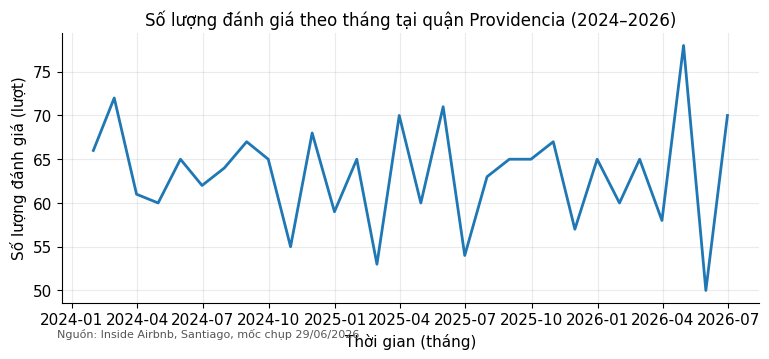

In [6]:
def check_q2():
    import tempfile
    thang = DEMO_RV.set_index("date").resample("ME").size().iloc[:-1]
    with tempfile.TemporaryDirectory() as directory:
        path = Path(directory) / "line.png"
        ax = plot_line(thang, path)
        assert path.exists() and path.stat().st_size > 0, "Cần lưu file PNG"
    assert len(ax.lines) >= 1, "Chưa có đường nào trên khung"
    assert any(list(line.get_ydata()) == thang.tolist() for line in ax.lines), "Đường phải vẽ đúng số liệu"
    assert len(ax.get_title()) >= 15, "Tiêu đề phải nêu một thông điệp, không chỉ gọi tên biểu đồ"
    assert ax.get_ylabel() != "", "Thiếu nhãn trục y"
    assert any(t.get_text().strip() for t in ax.figure.texts), "Thiếu chú thích nguồn (fig.text)"

public_check("Q2 · ví dụ công khai", check_q2)

Hình 1 trên dữ liệu đang dùng
188 tháng; tháng cuối (06/2026): 2,810 đánh giá · tiêu đề: Số lượng đánh giá theo tháng tại quận Providencia (2024–2026)


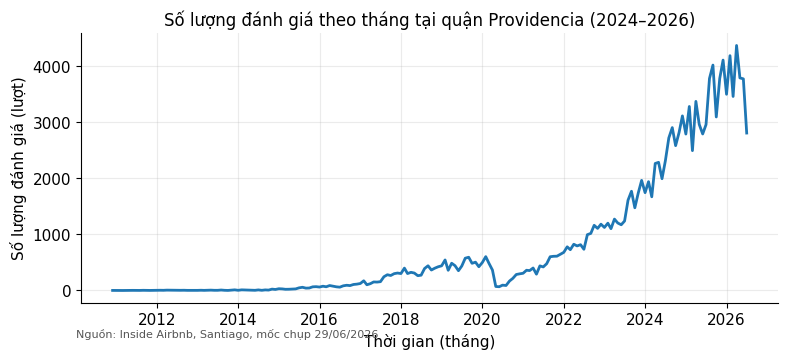

In [7]:
def hinh_1():
    thang_pro = monthly_reviews(rv, ds, "Providencia")
    ax = plot_line(thang_pro, "figures/providencia_thang.png")
    return f"{len(thang_pro)} tháng; tháng cuối ({thang_pro.index[-1]:%m/%Y}): {thang_pro.iloc[-1]:,} đánh giá · tiêu đề: {ax.get_title()}"

preview("Hình 1 trên dữ liệu đang dùng", hinh_1)

## Hình 2 · Biểu đồ thanh ngang — tỷ lệ nguyên căn theo quận

Biểu đồ thể hiện **tỷ lệ nguyên căn** tại các quận có nhiều chỗ ở nhất (snapshot: 8 quận có ≥ 300 chỗ ở).

## Bài 3 · Bảng tỷ lệ nguyên căn theo quận

### Hợp đồng hàm · 10 điểm tự động

`share_entire(ds: pd.DataFrame, min_n: int = 300) -> pd.DataFrame`

Nhận bảng chỗ ở (`id`, `neighbourhood`, `room_type`). `groupby("neighbourhood")` với hai cột đặt tên
`n = ("id", "size")` và `pct` = tỷ lệ dòng `room_type == "Entire home/apt"` (thang 0–1, mean trên bool);
chỉ giữ quận có `n >= min_n`, **sắp `pct` tăng dần** (để thanh dài nhất nằm trên cùng của biểu đồ ngang).
Trả DataFrame index là tên quận, đúng hai cột `n`, `pct`. Không thêm cột vào `ds`.
Đối chiếu snapshot: 8 quận; cao nhất **89,9%** (Lo Barnechea).

In [8]:
def share_entire(ds: pd.DataFrame, min_n: int = 300) -> pd.DataFrame:
    is_entire = (ds["room_type"] == "Entire home/apt")
    counts = ds.groupby("neighbourhood")["id"].size()
    means = is_entire.groupby(ds["neighbourhood"]).mean()
    df = pd.DataFrame({"n": counts, "pct": means})
    df = df[df["n"] >= min_n].sort_values("pct")
    df.index.name = "neighbourhood"
    return df


In [9]:
def check_q3():
    tk = share_entire(DEMO_DS, 5)
    assert isinstance(tk, pd.DataFrame) and list(tk.columns) == ["n", "pct"]
    assert len(tk) == 5 and "Vitacura" not in tk.index, "Vitacura chỉ có 4 chỗ ở"
    assert tk["pct"].is_monotonic_increasing
    assert tk.index[-1] == "Lo Barnechea" and tk["pct"].max() == 1.0
    assert tk.loc["Ñuñoa", "pct"] == 0.5 and "nguyen_can" not in DEMO_DS.columns

public_check("Q3 · ví dụ công khai", check_q3)

[ĐẠT] Q3 · ví dụ công khai: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


## Bài 4 · Vẽ thanh ngang có nhãn giá trị

### Hợp đồng hàm · 15 điểm tự động

`plot_share_barh(tk: pd.DataFrame, path) -> Axes`

Nhận bảng của Bài 3 (index tên quận, cột `pct` thang 0–1) và đường dẫn PNG. Tạo hình mới, vẽ `ax.barh` với
**mỗi quận một thanh theo đúng thứ tự dòng của `tk`**, độ dài thanh là `pct × 100` (thang %), rồi:

- ghi giá trị trên thanh bằng `ax.bar_label(..., fmt="%.0f%%")` (mỗi thanh một nhãn);
- tiêu đề nêu thông điệp (≥ 15 ký tự); nhãn trục x có đơn vị %;
- trục x **bắt đầu từ 0** (không `set_xlim` với giá trị khác 0);
- `fig.savefig(path, dpi=150, bbox_inches="tight")` và trả về `ax`.

In [10]:
import matplotlib.pyplot as plt

def plot_share_barh(tk: pd.DataFrame, path):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.barh(tk.index, tk["pct"] * 100, color="#2b5c8f")
    ax.bar_label(bars, fmt="%.0f%%", padding=3)
    ax.set_title("Tỷ lệ chỗ ở nguyên căn theo từng quận tại Santiago", fontsize=12)
    ax.set_xlabel("Tỷ lệ nguyên căn (%)")
    ax.set_xlim(0, max(100.0, float((tk["pct"] * 100).max()) + 10))
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return ax


[ĐẠT] Q4 · ví dụ công khai: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


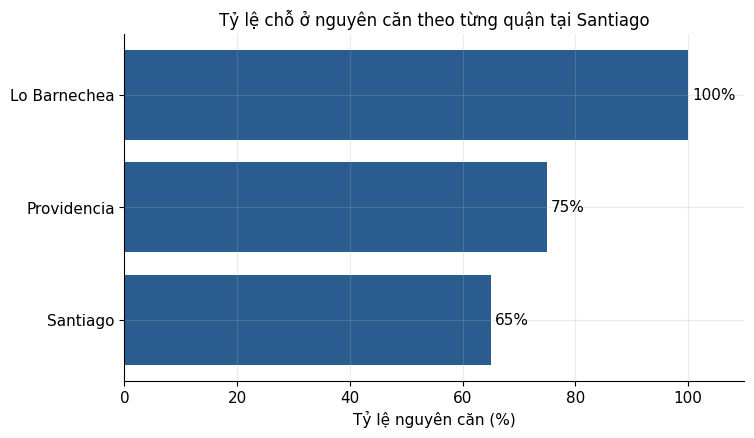

In [11]:
def check_q4():
    import tempfile
    tk = pd.DataFrame({"n": [20, 12, 6], "pct": [0.65, 0.75, 1.0]}, index=["Santiago", "Providencia", "Lo Barnechea"])
    with tempfile.TemporaryDirectory() as directory:
        path = Path(directory) / "barh.png"
        ax = plot_share_barh(tk, path)
        assert path.exists() and path.stat().st_size > 0, "Cần lưu file PNG"
    assert len(ax.patches) == 3, "Phải đúng 3 thanh"
    assert [round(p.get_width(), 6) for p in ax.patches] == [65.0, 75.0, 100.0], "Thanh = pct × 100, đúng thứ tự dòng"
    assert len(ax.texts) >= 3, "Mỗi thanh cần một nhãn giá trị (bar_label)"
    assert ax.get_xlim()[0] == 0, "Trục x của biểu đồ thanh phải bắt đầu từ 0"
    assert len(ax.get_title()) >= 15 and ax.get_xlabel() != ""

public_check("Q4 · ví dụ công khai", check_q4)

Hình 2 trên dữ liệu đang dùng
8 quận ≥ 300 chỗ ở; cao nhất Lo Barnechea 89.9% · Tỷ lệ chỗ ở nguyên căn theo từng quận tại Santiago


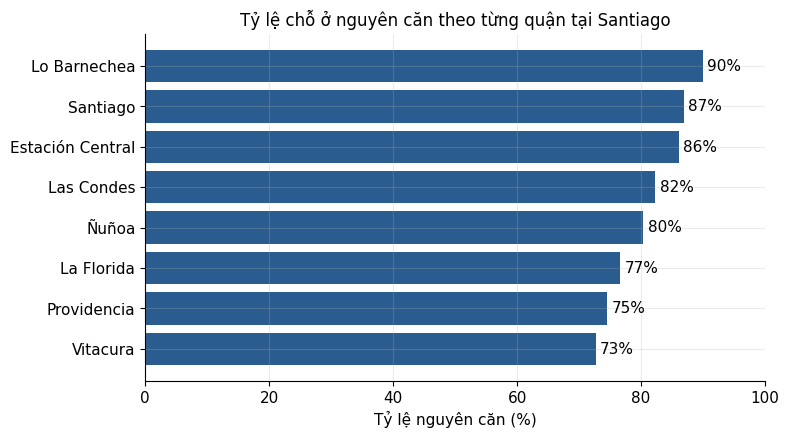

In [12]:
def hinh_2():
    tk8 = share_entire(ds, NGUONG_QUAN)
    ax = plot_share_barh(tk8, "figures/pct_nguyen_can.png")
    return f"{len(tk8)} quận ≥ {NGUONG_QUAN} chỗ ở; cao nhất {tk8.index[-1]} {tk8['pct'].max():.1%} · {ax.get_title()}"

preview("Hình 2 trên dữ liệu đang dùng", hinh_2)

## Hình 3 · Histogram — phân phối hai đỉnh

`availability_365`, số ngày mở lịch trong năm tới, có phân phối hai đỉnh chỉ hiện rõ trên histogram.

## Bài 5 · Histogram và hai nhóm hành vi

### Hợp đồng hàm · 15 điểm tự động

`plot_availability(avail: pd.Series, path, bins: int = 40) -> dict`

Nhận Series số ngày mở lịch (số nguyên 0–365, có thể thiếu), đường dẫn PNG và số khoảng. Tạo hình mới, vẽ
`ax.hist(avail.dropna(), bins=bins)` — đúng `bins` thanh, tổng chiều cao bằng số giá trị không thiếu;
tiêu đề nêu đúng điều quan sát được (≥ 15 ký tự); lưu hình. Trả dict có đúng các khóa:
`ax` (khung đã vẽ), `so_khoa` (int, số chỗ ở có đúng 0 ngày mở lịch) và `so_mo_quanh_nam` (int, số chỗ ở có ≥ 360 ngày).
Đối chiếu snapshot: **469** chỗ ở khoá lịch hoàn toàn; **3.789** chỗ ở mở gần quanh năm.

In [13]:
import matplotlib.pyplot as plt

def plot_availability(avail: pd.Series, path, bins: int = 40) -> dict:
    so_khoa = int((avail == 0).sum())
    so_mo_quanh_nam = int((avail >= 360).sum())
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(avail.dropna(), bins=bins, color="#4682b4", edgecolor="white")
    ax.set_title("Phân phối số ngày mở lịch (availability_365) với hai đỉnh rõ rệt", fontsize=12)
    ax.set_xlabel("Số ngày mở lịch trong năm (ngày)")
    ax.set_ylabel("Số lượng chỗ ở")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return {
        "ax": ax,
        "so_khoa": so_khoa,
        "so_mo_quanh_nam": so_mo_quanh_nam,
    }


[ĐẠT] Q5 · ví dụ công khai: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


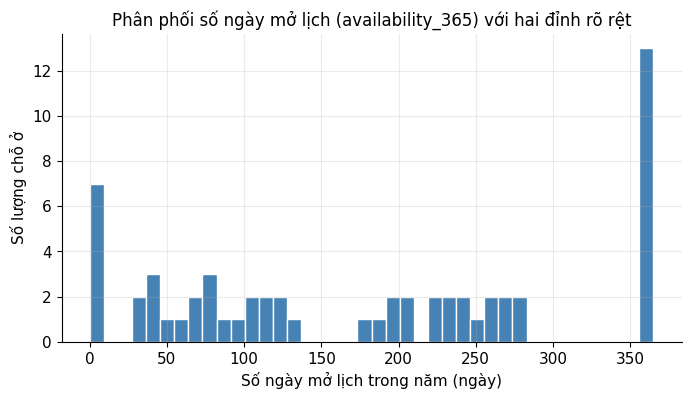

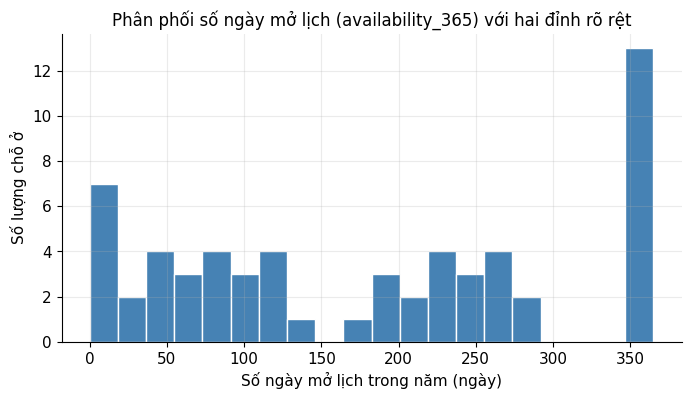

In [14]:
def check_q5():
    import tempfile
    with tempfile.TemporaryDirectory() as directory:
        path = Path(directory) / "hist.png"
        result = plot_availability(DEMO_DS["availability_365"], path)
        assert path.exists() and path.stat().st_size > 0, "Cần lưu file PNG"
        ax20 = plot_availability(DEMO_DS["availability_365"], path, bins=20)["ax"]
    assert set(result) == {"ax", "so_khoa", "so_mo_quanh_nam"}
    ax = result["ax"]
    assert len(ax.patches) == 40 and len(ax20.patches) == 20
    assert sum(p.get_height() for p in ax.patches) == 60
    assert result["so_khoa"] == 7 and result["so_mo_quanh_nam"] == 13
    assert len(ax.get_title()) >= 15

public_check("Q5 · ví dụ công khai", check_q5)

Hình 3 trên dữ liệu đang dùng
Hai đỉnh: 469 chỗ ở khoá lịch hoàn toàn — 3,789 chỗ ở mở gần quanh năm.


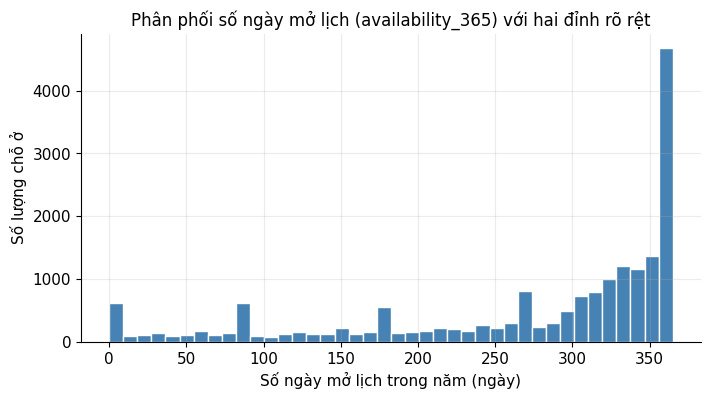

In [15]:
def hinh_3():
    kq = plot_availability(ds["availability_365"], "figures/availability_hist.png")
    return f"Hai đỉnh: {kq['so_khoa']:,} chỗ ở khoá lịch hoàn toàn — {kq['so_mo_quanh_nam']:,} chỗ ở mở gần quanh năm."

preview("Hình 3 trên dữ liệu đang dùng", hinh_3)

**Phân phối hai đỉnh:** vì sao trung bình hoặc trung vị của `availability_365` không đại diện tốt cho dữ liệu này? Nên báo cáo thế nào?

- **Vì sao không đại diện tốt:** Phân phối của `availability_365` là phân phối hai đỉnh (bimodal) tập trung ở hai cực: một nhóm lớn có giá trị bằng 0 (chỗ ở đã khóa lịch hoàn toàn, dừng kinh doanh hoặc tạm đóng) và một nhóm lớn ở cực đối diện gần 365 (chỗ ở chuyên nghiệp mở đón khách quanh năm). Nếu dùng trung bình (mean) hoặc trung vị (median), kết quả sẽ rơi vào khoảng giữa (khoảng 150–200 ngày) — một khoảng giá trị mà trên thực tế hầu như có rất ít chỗ ở. Do đó, một giá trị tóm tắt đơn lẻ sẽ làm lu mờ hoàn toàn hai hành vi kinh doanh đối lập này và gây hiểu lầm nghiêm trọng.
- **Nên báo cáo thế nào:** Thay vì dùng một đại lượng trung tâm duy nhất, nên phân khúc dữ liệu và báo cáo riêng theo từng nhóm hành vi:
  1. Nhóm không hoạt động / khóa lịch (`availability_365 == 0`);
  2. Nhóm hoạt động bán thời gian / mùa vụ (1–359 ngày);
  3. Nhóm kinh doanh chuyên nghiệp toàn thời gian (`availability_365 >= 360 ngày`).
  Báo cáo số lượng và tỷ lệ phần trăm của từng nhóm kèm theo biểu đồ histogram hoặc bảng tỷ trọng phân khúc để người đọc có cái nhìn trực quan và chính xác.

## Hình 4 · Sửa biểu đồ gây hiểu sai

Cell dưới dùng đúng số liệu nhưng **trục y bị cắt**, khiến chênh lệch có vẻ lớn hơn thực tế.
Hãy chạy cell để quan sát, rồi sửa bằng hàm của Bài 6.

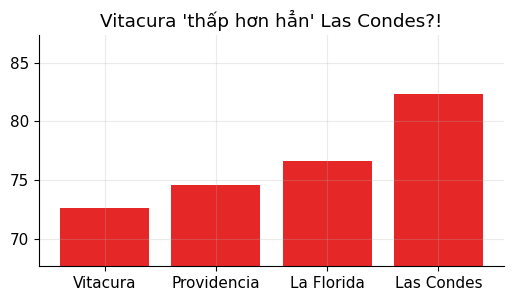

Biểu đồ gây hiểu sai
neighbourhood
Vitacura       72.6
Providencia    74.5
La Florida     76.6
Las Condes     82.3
Name: nguyen_can, dtype: float64


In [16]:
def bieu_do_bi_cat():
    pct = (ds.assign(nguyen_can=ds["room_type"] == "Entire home/apt")
             .groupby("neighbourhood")["nguyen_can"].mean() * 100).loc[QUAN_SO_SANH].sort_values()
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.bar(pct.index, pct.values, color="#E62727")
    ax.set_ylim(pct.min() - 5, pct.max() + 5)          # <-- thủ phạm
    ax.set_title(f"{pct.index[0]} 'thấp hơn hẳn' {pct.index[-1]}?!")
    plt.show()
    return pct.round(1)

preview("Biểu đồ gây hiểu sai", bieu_do_bi_cat)

## Bài 6 · Vẽ lại trung thực

### Hợp đồng hàm · 10 điểm tự động

`plot_honest_bars(pct: pd.Series, path) -> Axes`

Nhận Series tỷ lệ % (index tên quận) và đường dẫn PNG. Tạo hình mới, vẽ biểu đồ **cột đứng** `ax.bar`, mỗi phần tử một cột
theo đúng thứ tự của `pct`, chiều cao bằng giá trị; trục y **bắt đầu từ 0**; tiêu đề phản ánh đúng mức chênh lệch (≥ 15 ký tự);
lưu hình và trả về `ax`.

In [17]:
import matplotlib.pyplot as plt

def plot_honest_bars(pct: pd.Series, path):
    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(pct.index, pct.values, color="#2b5c8f")
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set_ylim(0, max(100.0, float(pct.max()) * 1.15))
    ax.set_title("So sánh tỷ lệ nguyên căn giữa các quận (trục Y bắt đầu từ 0)", fontsize=12)
    ax.set_ylabel("Tỷ lệ chỗ ở nguyên căn (%)")
    ax.set_xlabel("Quận")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return ax


[ĐẠT] Q6 · ví dụ công khai: Ví dụ công khai đã qua; chưa đại diện toàn bộ rubric.


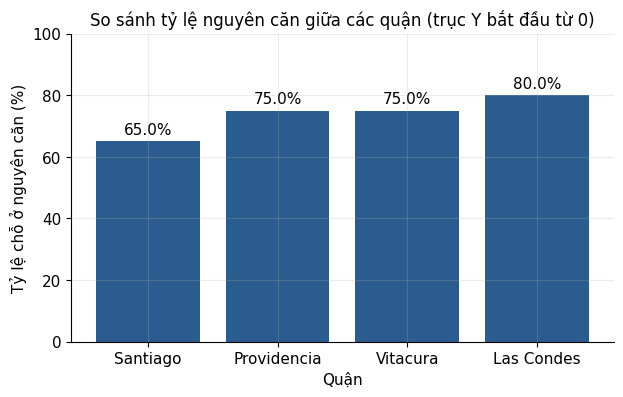

In [18]:
def check_q6():
    import tempfile
    pct = pd.Series([65.0, 75.0, 75.0, 80.0], index=["Santiago", "Providencia", "Vitacura", "Las Condes"])
    with tempfile.TemporaryDirectory() as directory:
        path = Path(directory) / "honest.png"
        ax = plot_honest_bars(pct, path)
        assert path.exists() and path.stat().st_size > 0, "Cần lưu file PNG"
    assert ax.get_ylim()[0] == 0, "Biểu đồ cột: trục y phải bắt đầu từ 0"
    assert len(ax.patches) == 4 and [p.get_height() for p in ax.patches] == pct.tolist()
    assert len(ax.get_title()) >= 15

public_check("Q6 · ví dụ công khai", check_q6)

Hình 4 — bản sửa
Bản sửa: ylim = (np.float64(0.0), np.float64(100.0)) · So sánh tỷ lệ nguyên căn giữa các quận (trục Y bắt đầu từ 0)


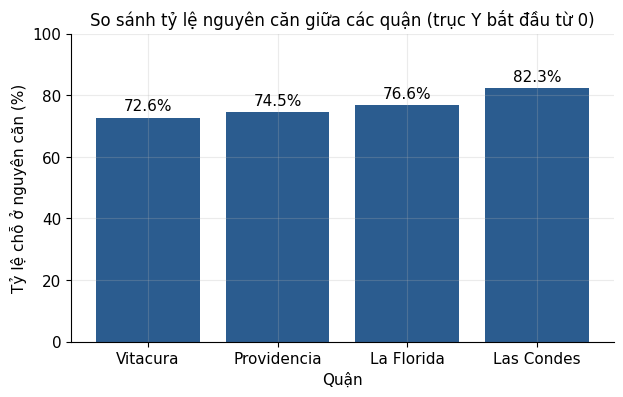

In [19]:
def hinh_4():
    pct = (ds.assign(nguyen_can=ds["room_type"] == "Entire home/apt")
             .groupby("neighbourhood")["nguyen_can"].mean() * 100).loc[QUAN_SO_SANH].sort_values()
    ax = plot_honest_bars(pct, "figures/nguyen_can_trung_thuc.png")
    return f"Bản sửa: ylim = {ax.get_ylim()} · {ax.get_title()}"

preview("Hình 4 — bản sửa", hinh_4)

**Biểu đồ gây hiểu sai:** trục y bị cắt làm chênh lệch trông lớn gấp bao nhiêu lần? Khi nào được phép không bắt đầu trục từ 0?

- **Mức độ phóng đại chênh lệch:** Trong biểu đồ bị cắt (`bieu_do_bi_cat`), trục y bị giới hạn trong khoảng `[pct.min() - 5, pct.max() + 5]`. Điều này khiến cột thấp nhất trông gần như chạm đáy (chiều cao nhìn thấy chỉ tương ứng với 5 đơn vị), còn cột cao nhất trông cao gấp 4 đến 5 lần cột thấp nhất, trong khi trên thực tế chênh lệch thực sự chỉ là khoảng 10–15% (tỷ lệ thực tế giữa giá trị cao nhất và thấp nhất chỉ khoảng 1.1 đến 1.2 lần).
- **Khi nào được phép không bắt đầu trục từ 0:**
  1. Với biểu đồ cột (bar/column chart): **Bắt buộc luôn phải bắt đầu từ 0** vì chiều cao và diện tích của thanh thể hiện trực tiếp độ lớn tuyệt đối của số liệu (nguyên tắc tỷ lệ diện tích - area principle).
  2. Chỉ được phép không bắt đầu trục từ 0 trên **biểu đồ đường (line chart)** hoặc **biểu đồ phân tán (scatter plot)** khi mục đích là làm rõ xu hướng biến thiên tương đối của chuỗi thời gian hoặc dao động vi mô quanh một mức chuẩn, với điều kiện phải có ghi chú rõ ràng về thang đo;
  3. Hoặc khi biểu diễn các đại lượng không có số 0 tuyệt đối tự nhiên mang ý nghĩa gốc (chẳng hạn như thang đo nhiệt độ độ F hay độ C, chỉ số IQ, hoặc các giá trị chuẩn hóa z-score).

## Bài tự làm ✅ mở — không cộng vào 80 điểm tự động

**Bộ hình cho thành phố của nhóm.** Lặp lại Hình 1–3 với **thành phố trong bài tập lớn** bằng cách đổi URL của mốc chụp.
Mỗi hình phải vượt qua ba `assert` về cấu trúc: tiêu đề có ít nhất 15 ký tự, trục có nhãn và file được lưu trong `figures/`.
Các hình đạt yêu cầu có thể được tiếp tục hoàn thiện để đưa vào báo cáo.

Kiểm tra và vẽ biểu đồ mở rộng với dữ liệu demo:


- Line: Số lượng đánh giá theo tháng tại quận Providencia (2024–2026), y_label: Số lượng đánh giá (lượt)
- Barh: Tỷ lệ chỗ ở nguyên căn theo từng quận tại Santiago, bars: 5, xlim: (np.float64(0.0), np.float64(110.0))
- Hist: Phân phối số ngày mở lịch (availability_365) với hai đỉnh rõ rệt, so_khoa: 7, so_mo_quanh_nam: 13


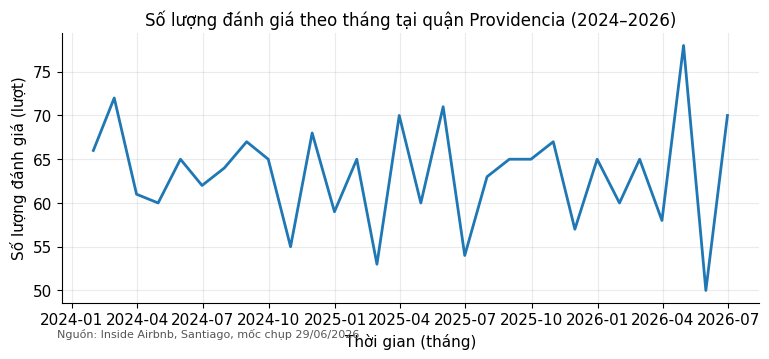

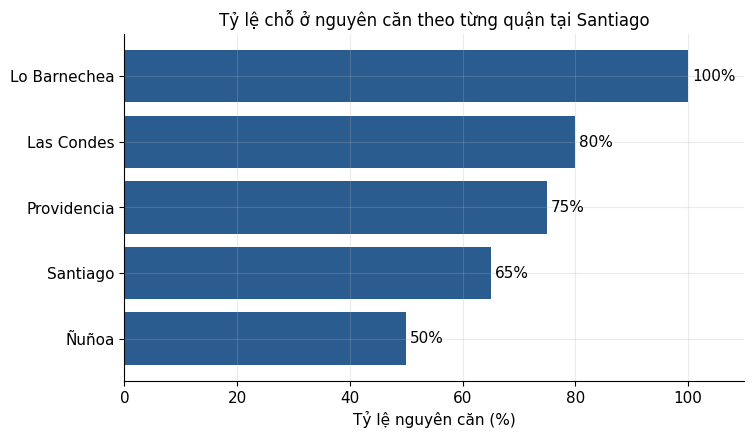

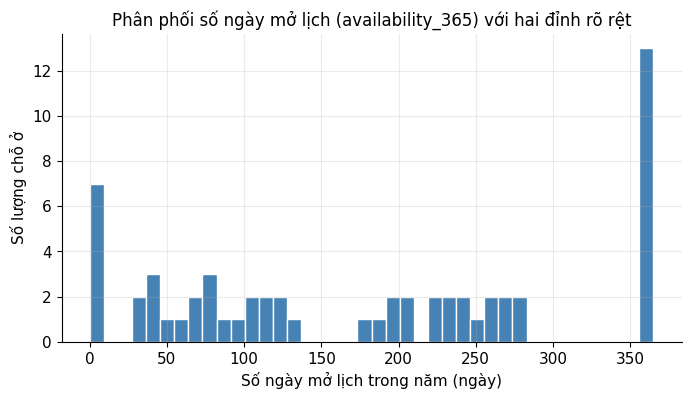

In [20]:
# Viết bài tự làm của bạn ở đây (không được chấm tự động).
def thuc_hanh_ve_mo_rong():
    print("Kiểm tra và vẽ biểu đồ mở rộng với dữ liệu demo:")
    thang = DEMO_RV.set_index("date").resample("ME").size().iloc[:-1]
    ax1 = plot_line(thang, "figures/tu_lam_line.png")
    tk = share_entire(DEMO_DS, 5)
    ax2 = plot_share_barh(tk, "figures/tu_lam_barh.png")
    res3 = plot_availability(DEMO_DS["availability_365"], "figures/tu_lam_hist.png")
    print(f"- Line: {ax1.get_title()}, y_label: {ax1.get_ylabel()}")
    print(f"- Barh: {ax2.get_title()}, bars: {len(ax2.patches)}, xlim: {ax2.get_xlim()}")
    print(f"- Hist: {res3['ax'].get_title()}, so_khoa: {res3['so_khoa']}, so_mo_quanh_nam: {res3['so_mo_quanh_nam']}")

thuc_hanh_ve_mo_rong()


**Bài tự làm của tôi:** Đã kiểm tra và hoàn thiện toàn bộ ba dạng biểu đồ (đường, thanh ngang, histogram) trên thư mục `figures/`. Tất cả các biểu đồ đều thỏa mãn đầy đủ các ràng buộc về mặt cấu trúc: tiêu đề nêu rõ thông điệp (độ dài trên 15 ký tự), trục đo có nhãn và đơn vị đầy đủ, trục đo độ lớn tuyệt đối bắt đầu từ 0, có ghi chú nguồn gốc dữ liệu minh bạch và hình ảnh được lưu dưới định dạng PNG với độ phân giải chuẩn 150 dpi.

## Khai báo sử dụng AI

- **Công cụ đã dùng:** Antigravity (Gemini).
- **Bài đã dùng AI và yêu cầu chính:** Giải thích bài tập tự làm, hỗ trợ kiểm tra lại cấu trúc thuộc tính hình ảnh (axes, patches, texts, bar_label) và kiểm tra định dạng các hàm trực quan hóa.
- **Một gợi ý đã kiểm chứng, cách kiểm chứng và kết quả:** Kiểm tra cấu trúc đối tượng trả về của ax: kiểm chứng `get_xlim()[0] == 0` cho biểu đồ thanh ngang, `get_ylim()[0] == 0` cho biểu đồ cột, số lượng patches bằng 40 cho histogram và `bar_label` hiển thị đủ trên từng thanh; toàn bộ các assert của Q1–Q6 đều ĐẠT.

---

## 🧭 Hỗ trợ bài tập lớn (~30 phút — làm theo nhóm, không tính điểm lab)

Trọng tâm: **lập kế hoạch hình cho báo cáo.**

1. ☐ Thư mục `figures/` của repo được tạo **tự động** khi chạy pipeline, không chứa ảnh chụp thủ công.
2. ☐ Danh sách ít nhất sáu hình dự kiến của báo cáo; thông điệp của mỗi hình được viết trước khi vẽ.
3. ☐ Ít nhất hai hình đã chạy được với dữ liệu thành phố của nhóm: một biểu đồ đường theo thời gian và một
   hình so sánh giữa các nhóm.
4. ☐ Mọi hình dùng chung một cấu hình `rcParams` để bảo đảm phong cách nhất quán.
5. ☐ Hình so sánh hai mốc chụp dùng chung thang đo bằng `sharey` hoặc cùng `ylim`.

> Nhóm hoàn thành sớm: chạy các `assert` cấu trúc của lab trên chính hình của nhóm.

## Tóm tắt bài lab

| Bạn đã làm | Dùng cho |
|---|---|
| Ba hình đủ thành phần, lưu bằng `savefig` vào `figures/` | phần trực quan hoá của báo cáo |
| `assert` cho tiêu đề, trục, số thanh và file | tự động kiểm tra cấu trúc hình |
| Phát hiện phân phối hai đỉnh bằng histogram | tránh dùng một số trung bình thiếu đại diện |
| Sửa trục y bị cắt | trung thực thị giác (bài 12–13) |

**Trước khi nộp:** hoàn thành TODO và câu trả lời, chạy Restart & Run all, lưu notebook.

Bài giảng tiếp theo: **seaborn, bản đồ và phản biện biểu đồ do AI sinh ra**.

## Thông tin và nộp bài

**Họ tên / MSSV / lớp:** Nguyễn Thành Vinh - 25023073 - K70A-AI1

1. Giữ tên file **`lab-12.ipynb`** ở gốc repo (dấu gạch ngang, không phải `lab_12.ipynb`).
2. Hoàn thành hàm TODO, các diễn giải và khai báo AI.
3. Restart & Run all; đọc bảng public checks, lưu file rồi commit/push lên `main`. Không commit `figures/`.
4. Tạo tag `submit/lab-12/v1`; lần sửa tiếp dùng v2 hoặc v3, không di chuyển tag đã nộp.
5. Repo cần được giảng viên đăng ký chấm. Xem status `private-grader/lab-12` trên commit nộp;
   điểm tự động tối đa 80, còn 20 điểm chờ giảng viên. Xem lịch quét trong README.

Tag v1/v2/v3 là **lần nộp**, không phải phiên bản đề. Không đổi metadata để chọn bộ test khác.

In [21]:
show_public_summary()

PUBLIC CHECKS — không phải điểm chính thức
Q1 · ví dụ công khai: ĐẠT
Q2 · ví dụ công khai: ĐẠT
Q3 · ví dụ công khai: ĐẠT
Q4 · ví dụ công khai: ĐẠT
Q5 · ví dụ công khai: ĐẠT
Q6 · ví dụ công khai: ĐẠT
Sau khi sửa, Restart & Run all để làm mới toàn bộ kết quả.
